Starting with a focus on the WEEKLY dataset
As shown in the Prophet model we saw significant improvements in Weekly Aggregation¶

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from statsmodels.api import tsa

In [2]:
%run include_functions.ipynb
%run evaluation_functions.ipynb
%run time_series_metrics.ipynb
#warnings.filterwarnings("ignore")

Introduce the dataset with the Date columns "parsed":
The parameter settings parsed are:

index_col = 'dt' Set the new datetime format column as the index

na_values=['nan','?'] Allows any occurences of 'nan' or '?' to be recognised as NaN.

parse_dates = [0] Specifies the index of the column that has to be parsed as datetime.

In [3]:
#df = pd.read_excel("C:/Users/pw347789/OneDrive - Oxfordshire County Council/Desktop/Cambridge Spark/PROJECT/RoadTrafficCollisions/df_ts_1.xlsx",  index_col='Date', parse_dates=["Date"])
df = pd.read_excel("C:/Users/pw347789/OneDrive - Oxfordshire County Council/Desktop/Cambridge Spark/PROJECT/RoadTrafficCollisions/Raw_data/Raw_ts_1.xlsx",  index_col='Date')#, parse_dates=["Date"])


df.drop(columns = 'Unnamed: 0', inplace =True)
df = df.drop(columns = ['Daily range degC',
                       'Grass min °C',
                       'Rainfall mm raw incl traces',
                      'Tmax °C',
                       'Tmin °C',
                       'Max ≥ 25.0°C',	
                        'Max ≥ 30.0°C'	,
                        'Min ≥ 15.0 °C'	,
                        'Max < 0 °C',
                       'Rain day (0.2 mm or more)',
                       'Wet day (1.0 mm or more)'
                      ])

df #= df['Date'].loc[:'2025-12-30']

#df.rename(columns = {'Parsed_Date':'Date'}, inplace = True)
df.tail(3)


,Incident_Count,Daily Tmean °C,Air frost 0/1,Ground frost 0/1,Rainfall mm 1 dpl no traces,Sunshine duration h,Nil sunshine,12 h sunshine
Date,,,,,,,,
2025-12-29,0,5.2,0,0.0,0.0,0.0,1,0
2025-12-30,0,4.4,0,1.0,0.0,1.0,0,0
2025-12-31,0,0.9,1,1.0,0.0,5.5,0,0


This dataset contains multivariate time series data describing the weather conditions and Incident_count per day.

It spans January 2015 to December 2025, with the data recorded at dailyintervals:

In [4]:
#print(f'df time range:\nfrom: {df.Date[0]}\nto:   {df.Date[-1]}')

Before beginning any analysis we need to explore the data and ensure it is clean and in a suitable format.

Let's first check the data types to be sure they are in the correct format

In [5]:
df.dtypes

Incident_Count                   int64
Daily Tmean °C                 float64
Air frost 0/1                    int64
Ground frost 0/1               float64
Rainfall mm 1 dpl no traces    float64
Sunshine duration h            float64
Nil sunshine                     int64
12 h sunshine                    int64
dtype: object

#### Ensure target column exists and contains no unexpected missing values

In [6]:
assert 'Incident_Count' in df.columns, "Target column missing from input dataset."

#### Ensure there are no duplictions of Date in Time range

In [7]:
df_no_index = df.reset_index()
assert df_no_index['Date'].nunique() == len(df_no_index)

In [8]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4018 entries, 2015-01-01 to 2025-12-31
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Incident_Count               4018 non-null   int64  
 1   Daily Tmean °C               4014 non-null   float64
 2   Air frost 0/1                4018 non-null   int64  
 3   Ground frost 0/1             3981 non-null   float64
 4   Rainfall mm 1 dpl no traces  4018 non-null   float64
 5   Sunshine duration h          4018 non-null   float64
 6   Nil sunshine                 4018 non-null   int64  
 7   12 h sunshine                4018 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 282.5 KB


#### Check for null values present, by feature

In [9]:
nulls = null_count(df)
nulls

,Field,Null Count,Null Pct
0,Incident_Count,0,0.0
1,Daily Tmean °C,4,0.1
2,Air frost 0/1,0,0.0
3,Ground frost 0/1,37,0.9
4,Rainfall mm 1 dpl no traces,0,0.0
5,Sunshine duration h,0,0.0
6,Nil sunshine,0,0.0
7,12 h sunshine,0,0.0


In [10]:
null_features = nulls[null_count(df)['Null Count'] != 0]
null_features

,Field,Null Count,Null Pct
1,Daily Tmean °C,4,0.1
3,Ground frost 0/1,37,0.9


In [11]:
# Force a weekly time series anchored on Wednesdays
df_weekly = df.asfreq('W-SUN')
df_weekly.sample(4)

,Incident_Count,Daily Tmean °C,Air frost 0/1,Ground frost 0/1,Rainfall mm 1 dpl no traces,Sunshine duration h,Nil sunshine,12 h sunshine
Date,,,,,,,,
2019-08-25,2,23.4,0,0.0,0.0,11.8,0,0
2018-04-29,1,6.8,0,0.0,0.2,0.0,1,0
2019-11-17,1,6.1,0,0.0,0.6,0.5,0,0
2020-08-30,0,13.5,0,0.0,0.1,3.7,0,0


In [12]:
df_weekly_no_index = df_weekly.reset_index()
assert df_weekly_no_index['Date'].nunique() == len(df_weekly_no_index)

In [13]:
null_features = nulls[null_count(df_weekly)['Null Count'] != 0]
null_features

,Field,Null Count,Null Pct
3,Ground frost 0/1,37,0.9


In [14]:
df_weekly = df_weekly.ffill()
df_weekly = df_weekly.astype(float)
df_weekly.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 574 entries, 2015-01-04 to 2025-12-28
Freq: W-SUN
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Incident_Count               574 non-null    float64
 1   Daily Tmean °C               574 non-null    float64
 2   Air frost 0/1                574 non-null    float64
 3   Ground frost 0/1             574 non-null    float64
 4   Rainfall mm 1 dpl no traces  574 non-null    float64
 5   Sunshine duration h          574 non-null    float64
 6   Nil sunshine                 574 non-null    float64
 7   12 h sunshine                574 non-null    float64
dtypes: float64(8)
memory usage: 40.4 KB


In [15]:
nulls_weekly = null_count(df_weekly)
nulls_weekly

,Field,Null Count,Null Pct
0,Incident_Count,0,0.0
1,Daily Tmean °C,0,0.0
2,Air frost 0/1,0,0.0
3,Ground frost 0/1,0,0.0
4,Rainfall mm 1 dpl no traces,0,0.0
5,Sunshine duration h,0,0.0
6,Nil sunshine,0,0.0
7,12 h sunshine,0,0.0


Visualise the data We can now begin to visualise the data and decide on the problem we would like to investigate.

What is the shape of the dataframe df?
Store your answer in a variable called df_shape**

In [16]:
df_weekly_shape = df_weekly.shape
df_weekly_shape

(574, 8)

In [17]:
df_weekly.columns
df_weekly= df_weekly[['Daily Tmean °C',  'Ground frost 0/1','Air frost 0/1',
       'Rainfall mm 1 dpl no traces', 'Sunshine duration h', 'Nil sunshine',
       '12 h sunshine', 'Incident_Count']]
df_weekly.head(3)

,Daily Tmean °C,Ground frost 0/1,Air frost 0/1,Rainfall mm 1 dpl no traces,Sunshine duration h,Nil sunshine,12 h sunshine,Incident_Count
Date,,,,,,,,
2015-01-04,2.8,1.0,1.0,0.2,0.0,1.0,0.0,0.0
2015-01-11,6.3,1.0,0.0,0.2,3.3,0.0,0.0,0.0
2015-01-18,2.6,1.0,0.0,0.0,4.3,0.0,0.0,0.0


In [18]:
df_weekly = remove_correlated(df_weekly, 0.5)
df_weekly.head(3)

,Daily Tmean °C,Air frost 0/1,Rainfall mm 1 dpl no traces,Sunshine duration h,Incident_Count
Date,,,,,
2015-01-04,2.8,1.0,0.2,0.0,0.0
2015-01-11,6.3,0.0,0.2,3.3,0.0
2015-01-18,2.6,0.0,0.0,4.3,0.0


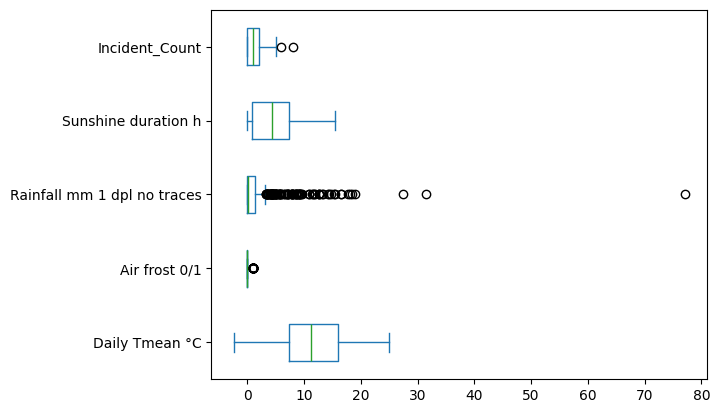

In [19]:
ax_1 = df_weekly.plot.box(vert=False)

In [20]:
from sklearn.preprocessing import StandardScaler, Normalizer

In [21]:
scaler = StandardScaler()
df_weekly_scaled = scaler.fit_transform(df_weekly)
df_weekly_scaled

array([[-1.62266027,  3.70377493, -0.3302593 , -1.14276411, -0.88525572],
       [-0.97663176, -0.26999481, -0.3302593 , -0.34726825, -0.88525572],
       [-1.65957618, -0.26999481, -0.3715822 , -0.1062089 , -0.88525572],
       ...,
       [-0.9581738 , -0.26999481, -0.3715822 , -0.66064541, -0.88525572],
       [-0.87511299, -0.26999481, -0.12364476, -1.04634037, -0.88525572],
       [-1.38270682, -0.26999481, -0.3715822 , -1.14276411, -0.88525572]],
      shape=(574, 5))

In [22]:
df_weekly_scaled = pd.DataFrame(data = df_weekly_scaled, columns = df_weekly.columns)
df_weekly_scaled.head(2)

,Daily Tmean °C,Air frost 0/1,Rainfall mm 1 dpl no traces,Sunshine duration h,Incident_Count
0,-1.622660,3.703775,-0.330259,-1.142764,-0.885256
1,-0.976632,-0.269995,-0.330259,-0.347268,-0.885256


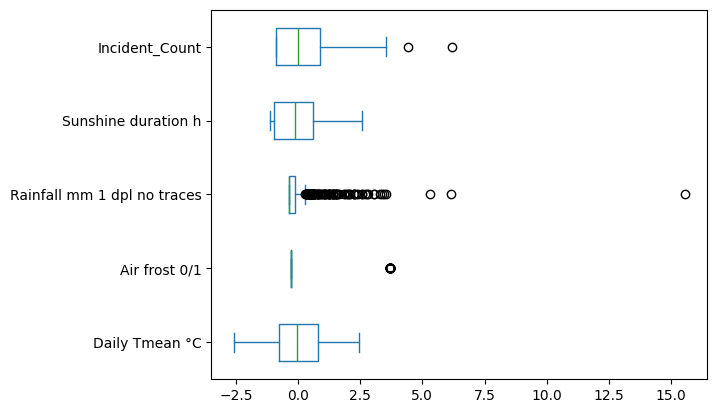

In [23]:
ax_1 = df_weekly_scaled.plot.box(vert=False)

In [24]:
normalizer = Normalizer()
df_weekly_normalized = normalizer.fit_transform(df_weekly)

In [25]:
df_weekly_norm = pd.DataFrame(data = df_weekly_normalized, columns = df_weekly.columns)
df_weekly_norm.head(2)

,Daily Tmean °C,Air frost 0/1,Rainfall mm 1 dpl no traces,Sunshine duration h,Incident_Count
0,0.939618,0.335578,0.067116,0.000000,0.0
1,0.885481,0.000000,0.028111,0.463824,0.0


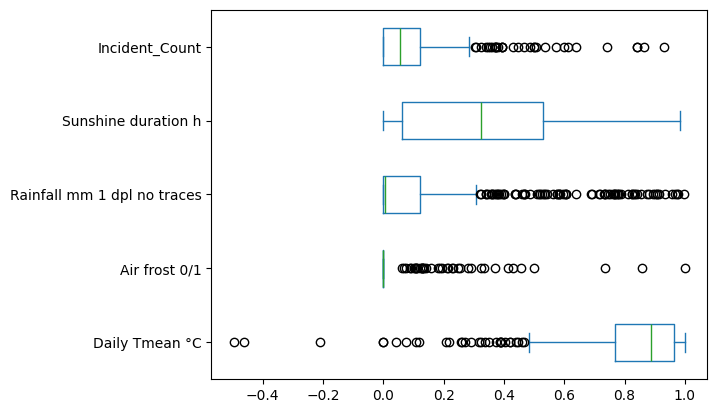

In [26]:
ax_2 = df_weekly_norm.plot.box(vert=False)

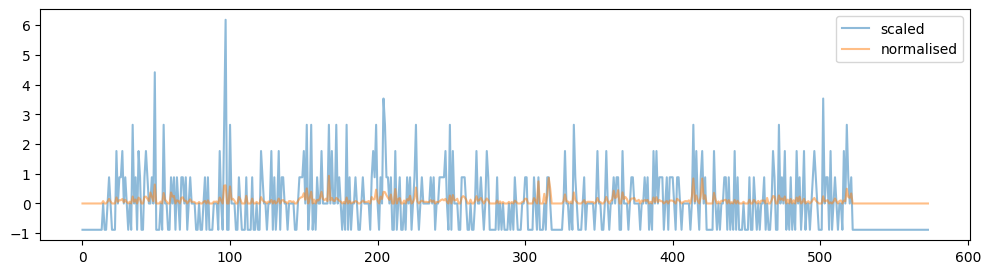

In [27]:
plt.figure(figsize=(12, 3))
#plt.plot(df.Incident_Count, label= 'df')
#plt.plot(df[['Incident_Count']]	,  alpha = 0.5, label = 'daily')
#plt.plot(df_weekly[['Incident_Count']]	,  alpha = 0.5, label = 'weekly')

plt.plot(df_weekly_scaled[['Incident_Count']]	,  alpha = 0.5, label = 'sacled')
plt.plot(df_weekly_norm[['Incident_Count']]	,  alpha = 0.5, label = 'normalized')
#plt.plot(monthly_mean.Incident_Count,  alpha = 0.5, label = 'monthly')
plt.legend(labels = ['scaled', 'normalised'])

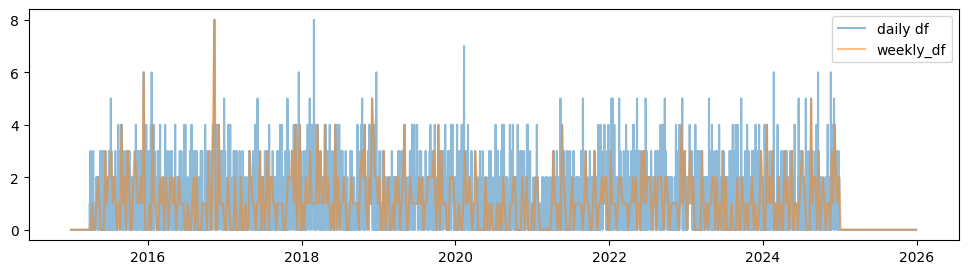

In [28]:
plt.figure(figsize=(12, 3))
#plt.plot(df.Incident_Count, label= 'df')
plt.plot(df[['Incident_Count']]	,  alpha = 0.5, label = 'daily')
plt.plot(df_weekly[['Incident_Count']],  alpha = 0.5, label = 'weekly')
plt.legend(labels = ['daily df', 'weekly_df'])

Before aggregation takes place we must split Features and Target

Targert will be subject to sum() aggregation

Features will be subject to mean() aggregation

In [29]:
# first isolate the target column:
df_target_weekly = df_weekly.iloc[:, -1:]
df_target_weekly.head(5)

,Incident_Count
Date,
2015-01-04,0.0
2015-01-11,0.0
2015-01-18,0.0
2015-01-25,0.0
2015-02-01,0.0


In [30]:
df_features = df_weekly.iloc[:, :-1]
df_features.head(5)

,Daily Tmean °C,Air frost 0/1,Rainfall mm 1 dpl no traces,Sunshine duration h
Date,,,,
2015-01-04,2.8,1.0,0.2,0.0
2015-01-11,6.3,0.0,0.2,3.3
2015-01-18,2.6,0.0,0.0,4.3
2015-01-25,5.0,0.0,0.0,1.8
2015-02-01,3.4,0.0,0.0,2.1


In [31]:
bools = []
for col in df_features.columns:
    if df_features[col].unique().sum() ==1:
        bools.append(col)
bools

['Air frost 0/1']

In [32]:
df_features['Air frost 0/1'] = df_features['Air frost 0/1'].astype('int64')
df_features.head(2)

,Daily Tmean °C,Air frost 0/1,Rainfall mm 1 dpl no traces,Sunshine duration h
Date,,,,
2015-01-04,2.8,1,0.2,0.0
2015-01-11,6.3,0,0.2,3.3


In [33]:
df_features.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 574 entries, 2015-01-04 to 2025-12-28
Freq: W-SUN
Data columns (total 4 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Daily Tmean °C               574 non-null    float64
 1   Air frost 0/1                574 non-null    int64  
 2   Rainfall mm 1 dpl no traces  574 non-null    float64
 3   Sunshine duration h          574 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 22.4 KB


In [34]:
## select the features of a continous datatype
continous_df_features = df_features.select_dtypes(include=['float64'])
continous_df_features.head(3)

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h
Date,,,
2015-01-04,2.8,0.2,0.0
2015-01-11,6.3,0.2,3.3
2015-01-18,2.6,0.0,4.3


In [35]:
## select the features of a continous datatype
continous_df_features = df_features.select_dtypes(include=['float64'])
continous_df_features.head(3)

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h
Date,,,
2015-01-04,2.8,0.2,0.0
2015-01-11,6.3,0.2,3.3
2015-01-18,2.6,0.0,4.3


In [36]:
integer_df_features = df_features.select_dtypes(include=['int64'])
integer_df_features.head(3)

,Air frost 0/1
Date,
2015-01-04,1
2015-01-11,0
2015-01-18,0


# AGGREGATION

In [37]:
df_target_weekly.head(7)

,Incident_Count
Date,
2015-01-04,0.0
2015-01-11,0.0
2015-01-18,0.0
2015-01-25,0.0
2015-02-01,0.0
2015-02-08,0.0
2015-02-15,0.0


In [38]:
agg = 'W'
#agg = 'ME'
agg

'W'

In [39]:
df_target_weekly = df_target_weekly.resample(agg).sum()
df_target_weekly.head(4)

,Incident_Count
Date,
2015-01-04,0.0
2015-01-11,0.0
2015-01-18,0.0
2015-01-25,0.0


In [40]:
integer_df_features_weekly = integer_df_features.resample(agg).sum()
integer_df_features_weekly.head(7)

,Air frost 0/1
Date,
2015-01-04,1
2015-01-11,0
2015-01-18,0
2015-01-25,0
2015-02-01,0
2015-02-08,1
2015-02-15,0


In [41]:
### continous features are to be aggregate according to thier mean() value:
continous_df_features_weekly = continous_df_features.resample(agg).mean()
continous_df_features_weekly = continous_df_features_weekly.rename(columns = {'Air frost 0/1':'Air Frost Day Count',  
                                          'Nil sunshine':'Nil Sunshine Day count',
                                          '12 h sunshine':'12 h sunshine Day Count' })

continous_df_features_weekly.head(3)

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h
Date,,,
2015-01-04,2.8,0.2,0.0
2015-01-11,6.3,0.2,3.3
2015-01-18,2.6,0.0,4.3


In [42]:
df_weekly = pd.concat([continous_df_features_weekly, integer_df_features_weekly, df_target_weekly ], axis=1)
df_weekly #= df_weekly.reset_index()
df_weekly.head(2)

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h,Air frost 0/1,Incident_Count
Date,,,,,
2015-01-04,2.8,0.2,0.0,1,0.0
2015-01-11,6.3,0.2,3.3,0,0.0


# MAPE
#### If a lot of target dtaa points are near to zero, then MAPE will inflate to infinity

In [43]:
daily_inc_count_freq = df.groupby('Incident_Count').size()
daily_inc_count_freq

Incident_Count
0    1619
1    1245
2     707
3     300
4     115
5      22
6       7
7       1
8       2
dtype: int64

In [44]:
daily_inc_count_freq = df_weekly.groupby('Incident_Count').size()
daily_inc_count_freq

Incident_Count
0.0    239
1.0    179
2.0    101
3.0     34
4.0     17
5.0      2
6.0      1
8.0      1
dtype: int64

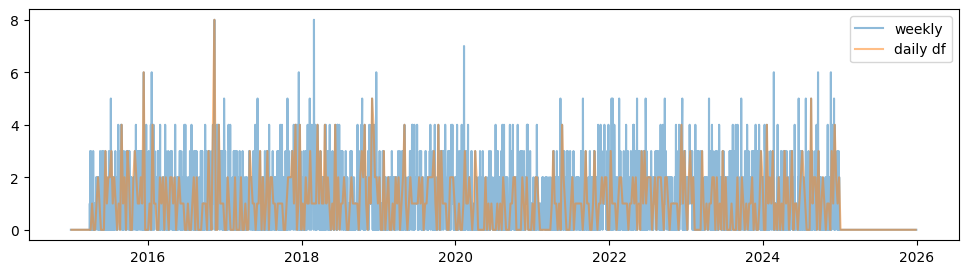

In [45]:
plt.figure(figsize=(12, 3))
#plt.plot(df.Incident_Count, label= 'df')
plt.plot(df[['Incident_Count']]	,  alpha = 0.5, label = 'daily')
plt.plot(df_weekly[['Incident_Count']]	,  alpha = 0.5, label = 'weekly')
#plt.plot(monthly_mean.Incident_Count,  alpha = 0.5, label = 'monthly')
plt.legend(labels = [ 'weekly','daily df'])

In [46]:
def plot_dataframe(dataframe):
    '''
    This function takes in a pandas dataframe and plots data for all columns provided in a grid of size n_rowsx2,
    where n_rows is ceil(cols/2) and cols is the number of provided columns in the dataframe.
    '''
    # Get the number of columns
    cols = dataframe.shape[1]
    
    # Create a figure of suitable size
    n_rows = int(np.ceil(cols/2))
    n_cols = 2
    fig, axs = plt.subplots(n_rows, n_cols, figsize = (30, 25));
    
    # Set the titles to be those of the dataframe variable names 
    columns = dataframe.columns
    
    # In each position, plot the relevant data
    counter = 0
    
    # If we have an odd number of subplots to make, do the last one separately
    if cols%2 != 0:
        n_rows -= 1
        axs[n_rows, 0].plot(dataframe[columns[-1]]);
        axs[n_rows, 0].set_title(columns[-1], fontweight = 'bold', size = 20);
        fig.delaxes(axs[n_rows, 1])  
        
    # Do the remaining plots 
    for i in range(n_rows):
        for j in range(n_cols):
            axs[i, j].plot(dataframe[columns[counter]]);
            axs[i, j].set_title(columns[counter], fontweight = 'bold', size = 20);
            counter += 1
    # Show the plot
    plt.show()
    return 

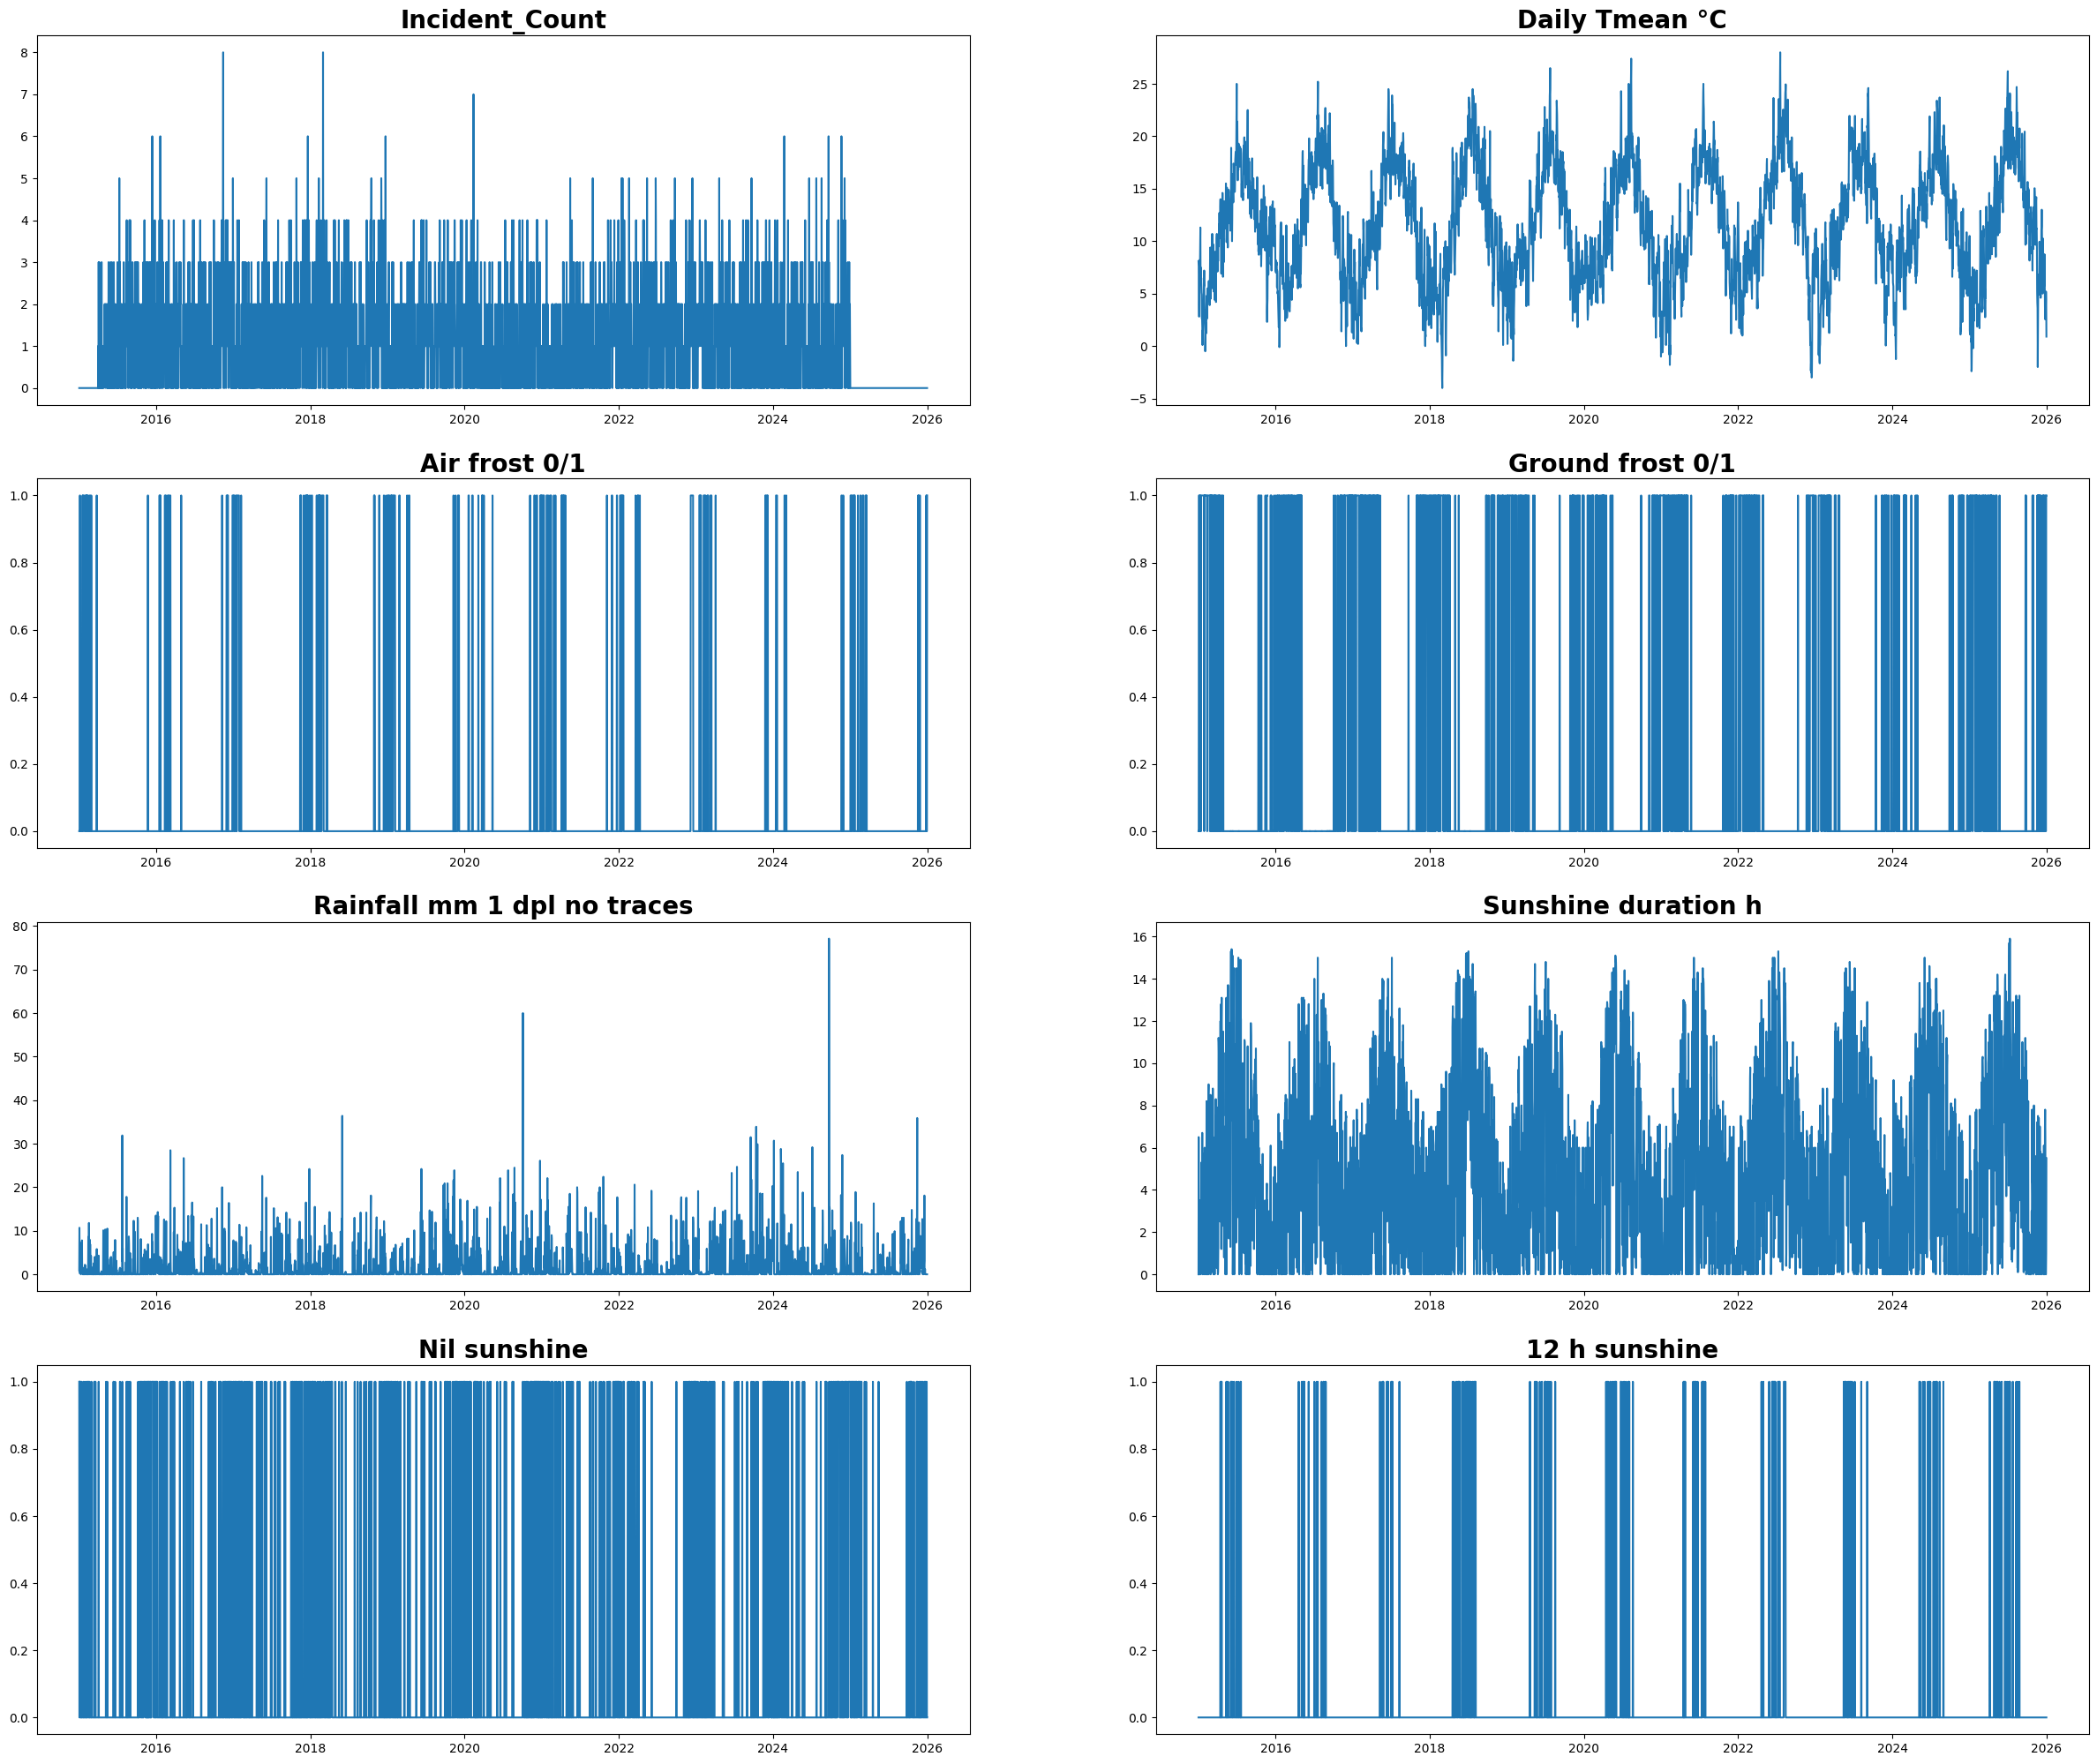

In [47]:
meandaily_plot = plot_dataframe(df.iloc[:,0:])

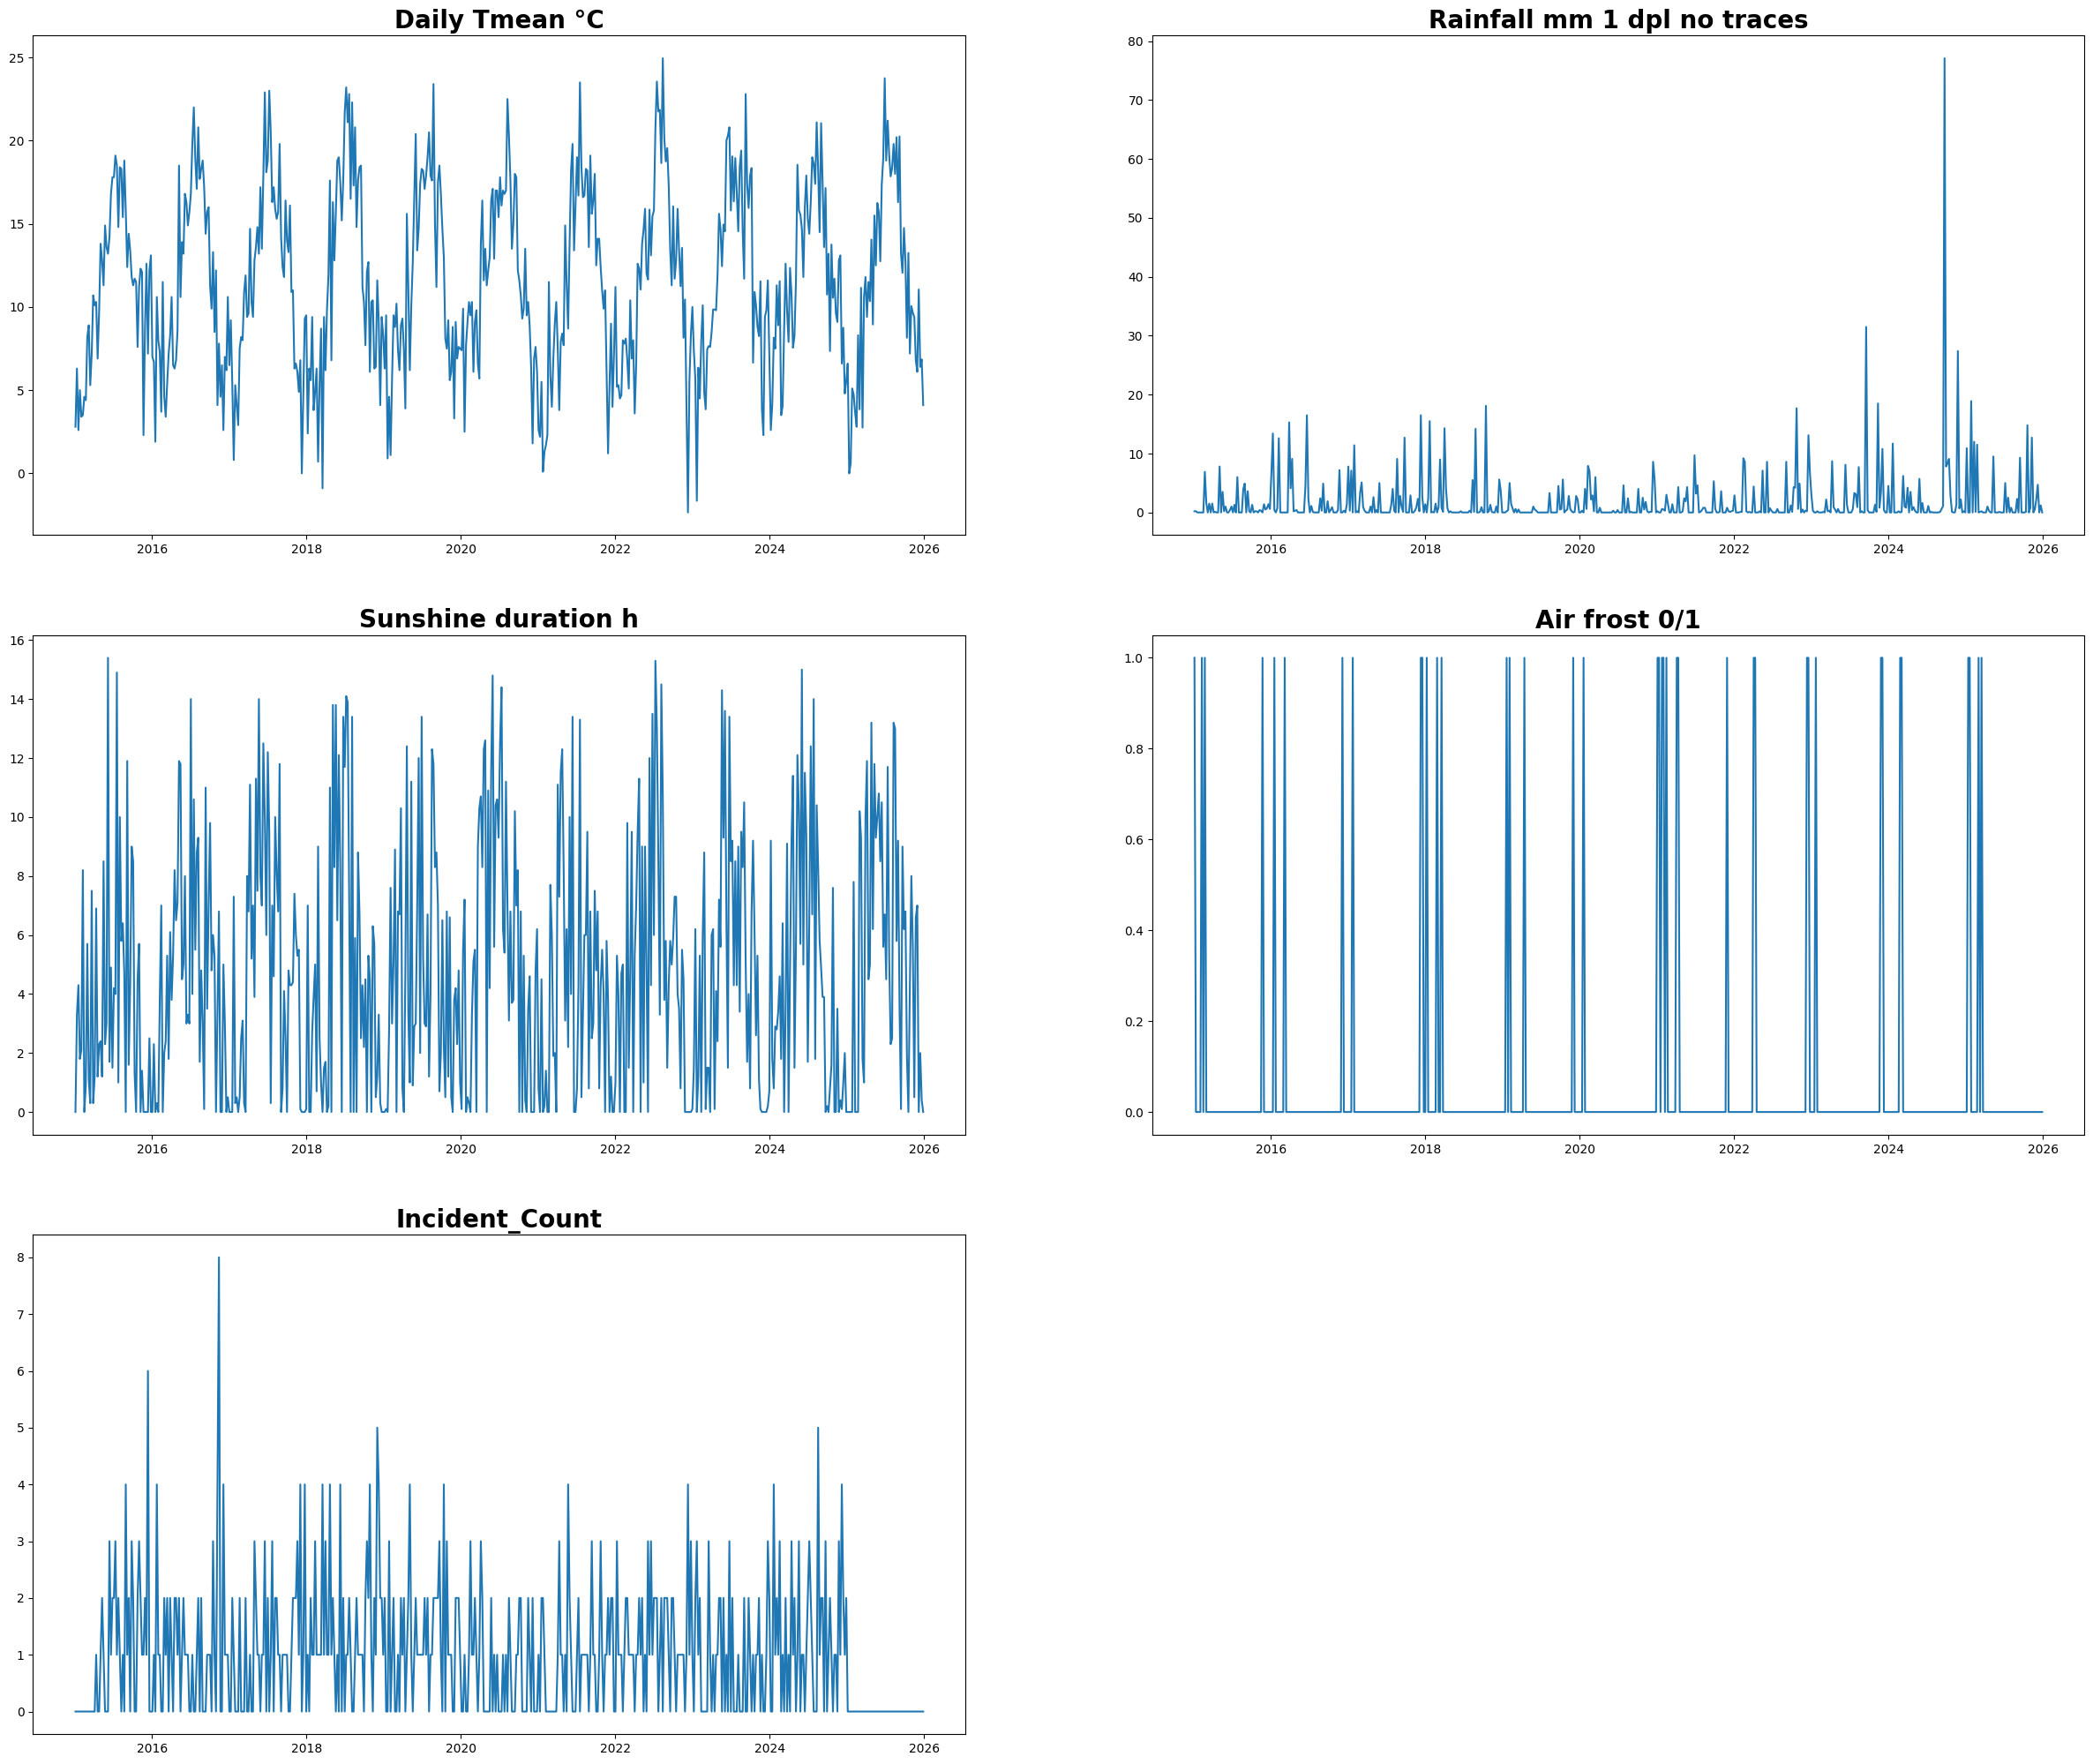

In [48]:
meanweekly_plot = plot_dataframe(df_weekly.iloc[:,0:])

In [49]:
def plot_twodfs(dataframe1, dataframe2):
    """
    A function which plots the data from each dataframe side by side.
    This is such that column 0 of each dataframe will be side by side in row 0 of a 2x2 figure, and so on for all columns. 
    NOTE: Therefore dataframe1 and dataframe2 must have the same number of columns.
    """
    if dataframe1.shape[1] != dataframe2.shape[1]:
        print('Error: dataframe1 and dataframe2 must have the same number of columns')
        return
    
    n_rows = dataframe1.shape[1]
    n_cols = 2
    fig, axs = plt.subplots(n_rows, 2, figsize = (30, 25))
    
    columns1 = dataframe1.columns
    columns2 = dataframe2.columns
    
    for i in range(n_rows):
        axs[i, 0].plot(dataframe1[columns1[i]]);
        axs[i, 0].set_title('Dataframe1: '+ columns1[i], fontweight = 'bold', size = 20);

        axs[i, 1].plot(dataframe2[columns2[i]]);
        axs[i, 1].set_title('Dataframe2: '+ columns2[i], fontweight = 'bold', size = 20);
    # Show the plot
    plt.show()    
    
    return

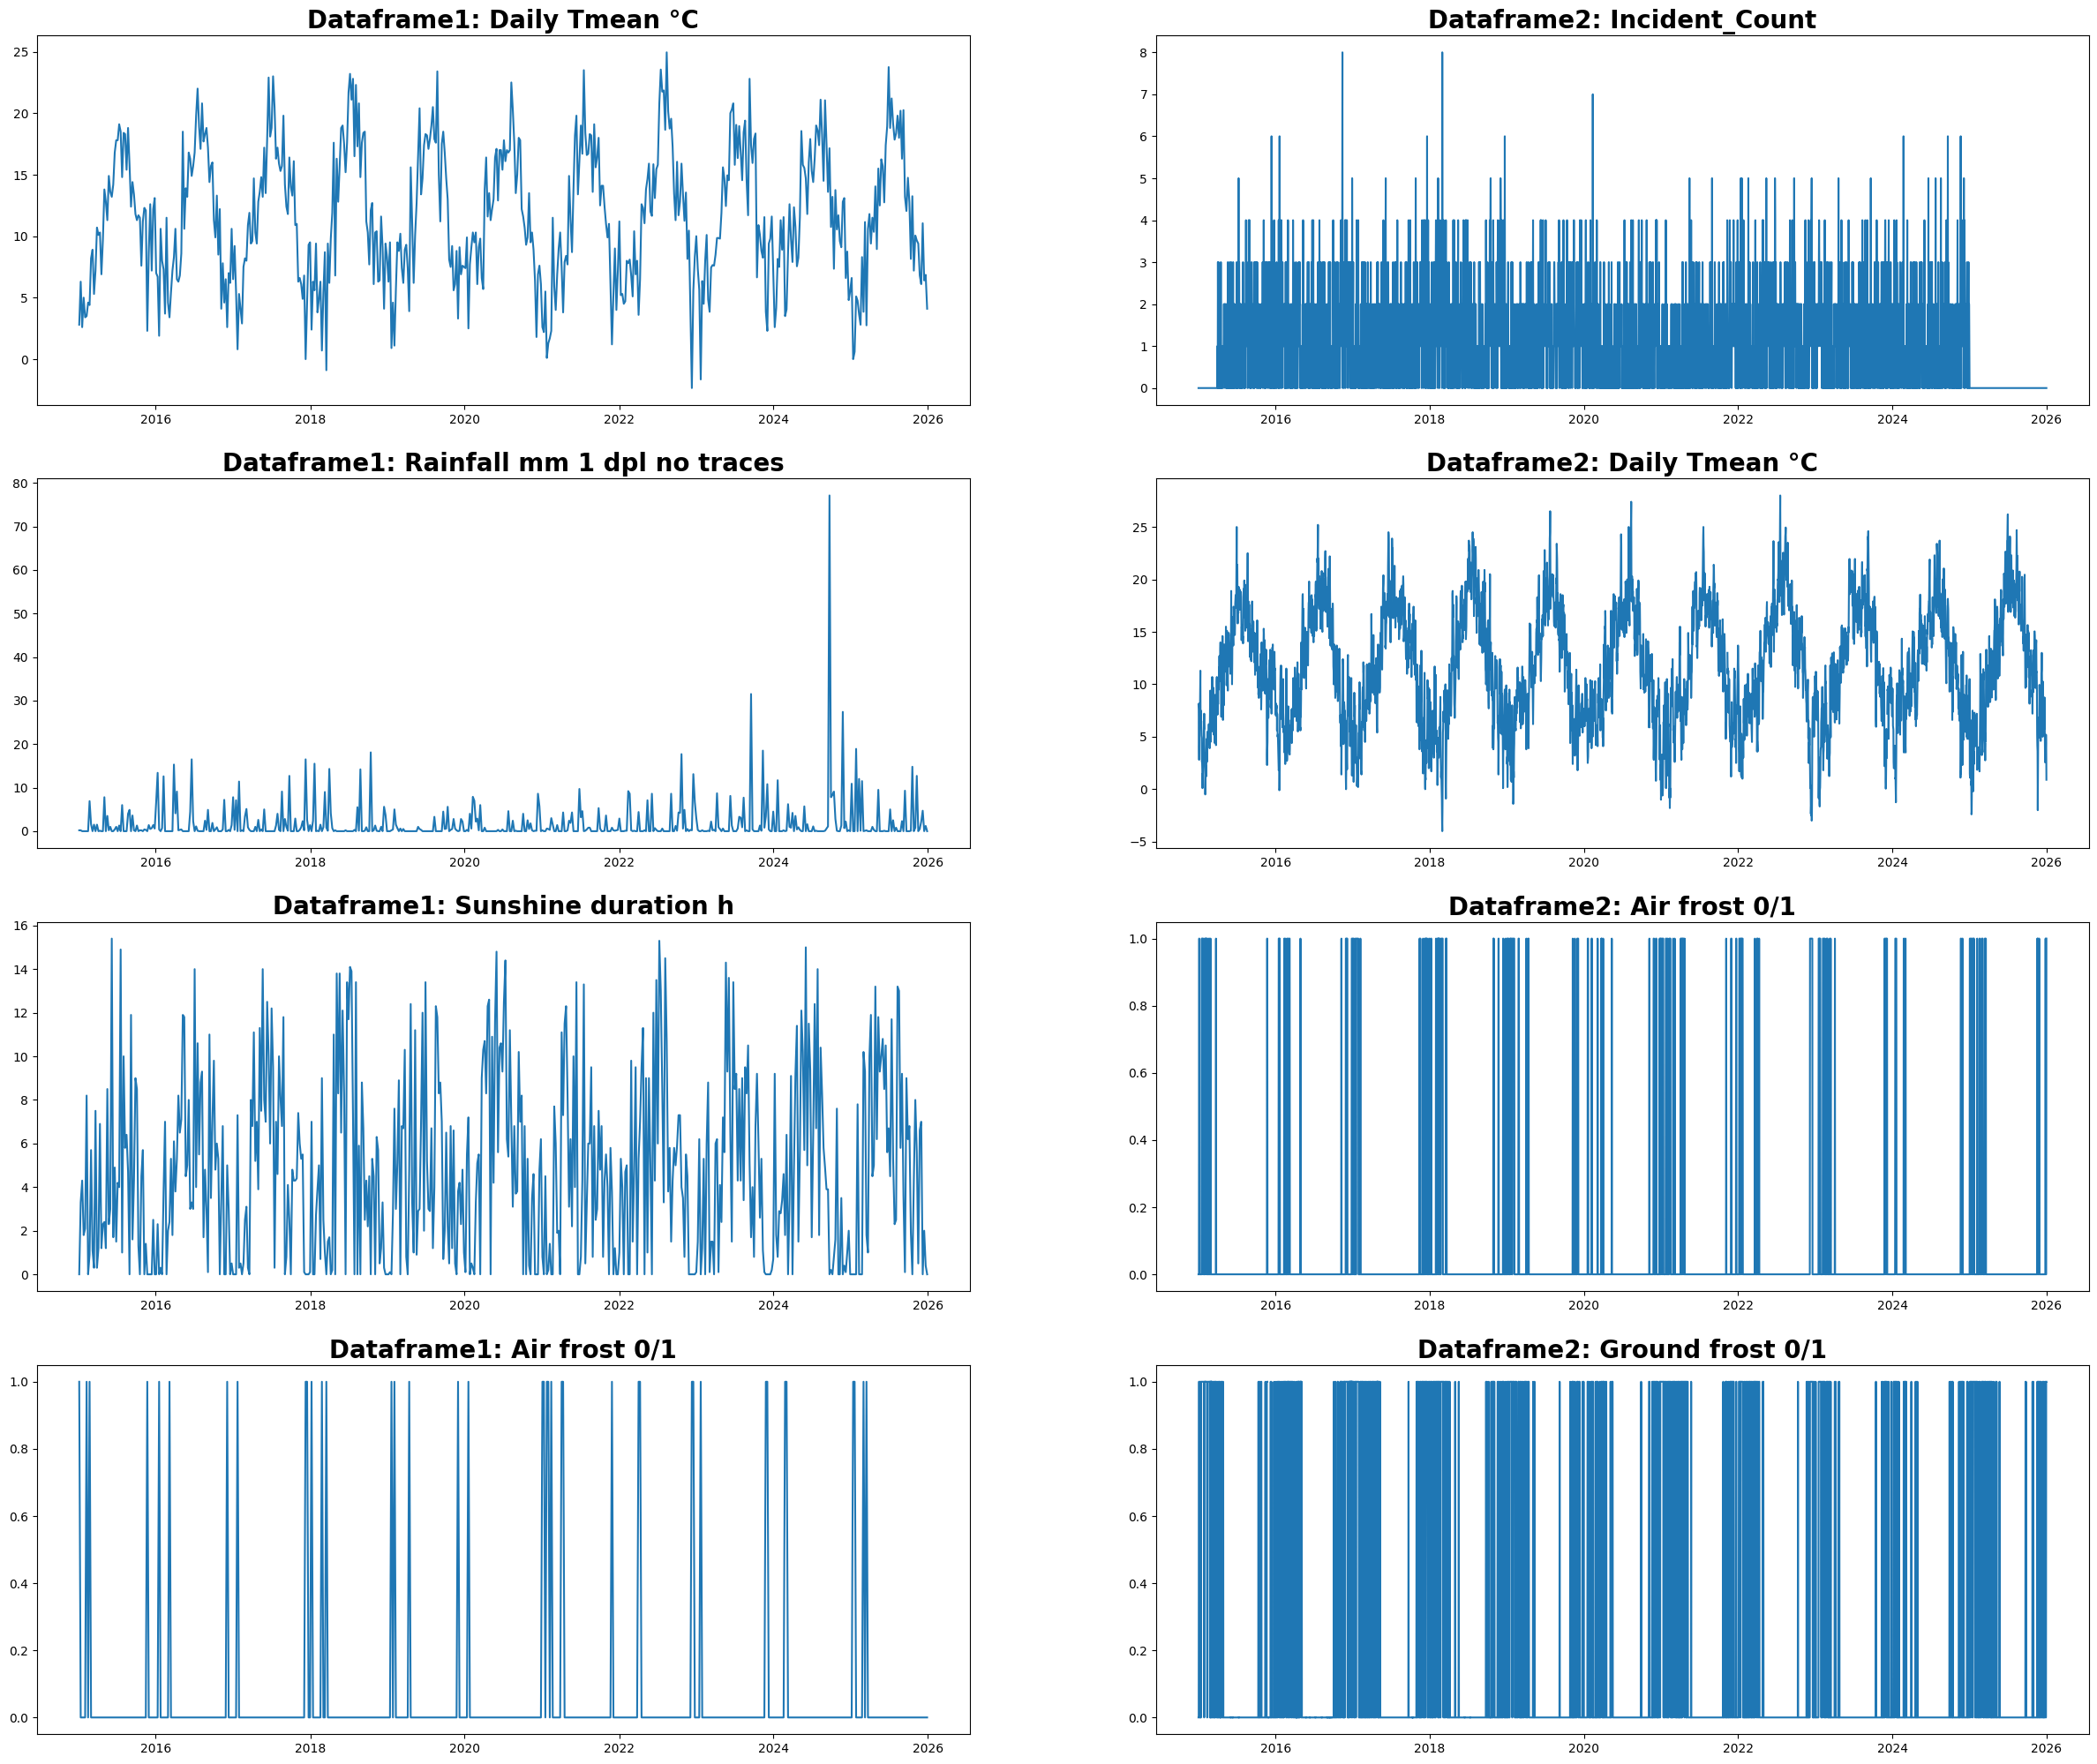

In [50]:
wmt = plot_twodfs(df_weekly.iloc[:,0:4], df.iloc[:,0:4])

In [51]:
## from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(df_weekly['Incident_Count']
                           , model='additive'
                           , period=52
                           ,two_sided=True, extrapolate_trend=0
                           )


trend = result.trend
seasonal = result.seasonal
residual = result.resid

In [52]:
def plot_decomposition(original, trend, seasonal, residual):
    """
    Plot the components of a decomposition. Pass in the original univarate data which was decomposed, and then the 
    3 resulting components, being the trend, seasonal and residual parts. 
    """
    # Plot the results
    plt.subplot(411)
    plt.plot(original, label = 'Original');
    plt.legend(loc = 'best')
    
    plt.subplot(412)
    plt.plot(trend, label = 'Trend');
    plt.legend(loc = 'best')
    
    plt.subplot(413)
    plt.plot(seasonal, label = 'Seasonality');
    plt.legend(loc = 'best')
    
    plt.subplot(414)
    plt.plot(residual, label = 'Residuals');
    
    plt.legend(loc = 'best')
    plt.tight_layout()
    plt.show()
    return

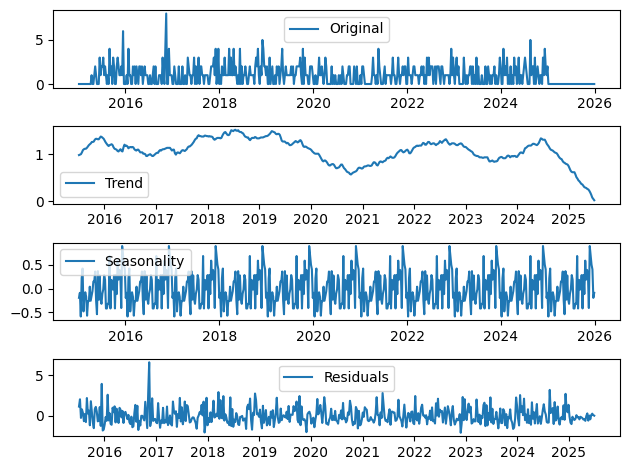

In [53]:
seasonality_plot = plot_decomposition(df_weekly['Incident_Count'], trend, seasonal, residual)

## SEASONALITY

Notes A time series can be correlated, as we just saw, with other time series. But it may also be correlated with itself. This is called autocorrelation and represents the similarity of a time series with a lagged version of itself. If a time series shows autocorrelation there might also be seasonality.

Let's take a look at an example. We will have to set a certain lag for computing the autocorrelation. In this case we are going to test an array of different lags. What we can see is that there seems to be autocorrelation when using multiples of 4, this may be exactly the effect of seasonality, which repeats every 4 time steps (quarters).

Text(0, 0.5, 'Autocorrelation')

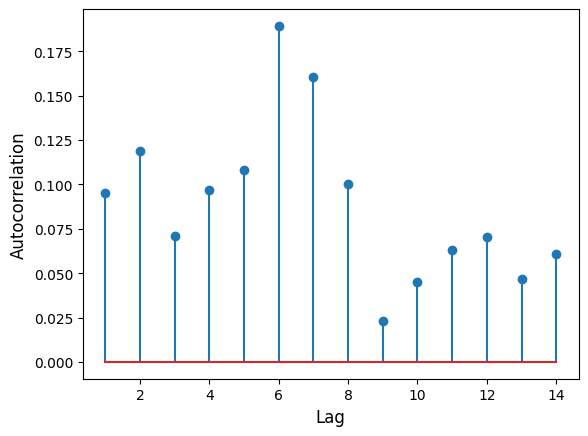

In [54]:
lags = range(1, 15)
autocorrs = [df_weekly.Incident_Count.autocorr(lag=lag) for lag in lags]
plt.figure()
plt.stem(lags, autocorrs)
plt.xlabel("Lag", fontsize=12)
plt.ylabel("Autocorrelation", fontsize=12)

## Partial autocorrelation

As we notice from the autocorrelation plot above, when seasonal effects are present, we see spikes in the autocorrelation at multiples of the seasonal component. For example, if we have annual seasonality in quarterly data, we see high autocorrelation at lag 4, but also at lags 8, 12, and so on.

The partial autocorrelation provides the correlation of a time series with lagged versions of itself, however it also removes linear effects from other lags. This makes it extremely useful for identifying the true correlated behaviour.

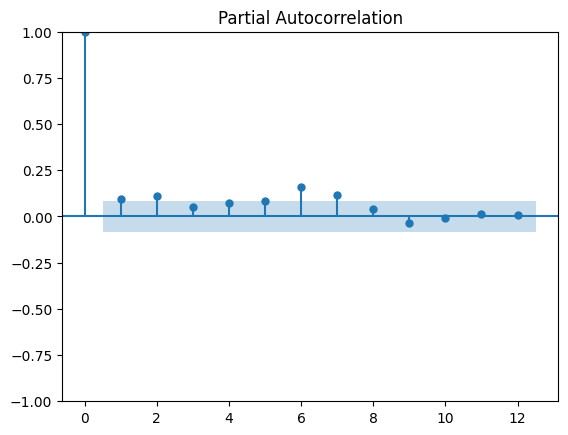

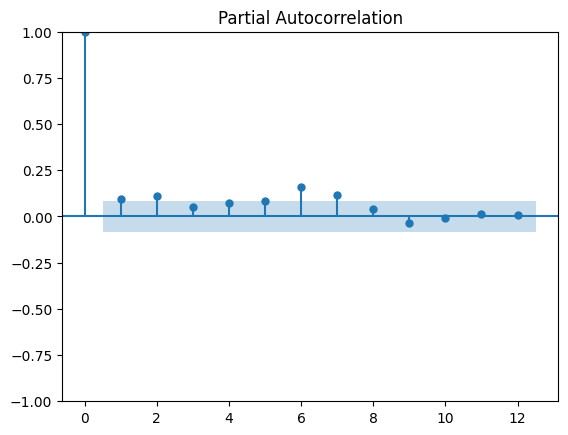

In [55]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(df_weekly.Incident_Count, method="ywm", lags=12)

## STATIONARITY

A stationary time series is one whose statistical properties—like mean, variance, and autocorrelation—do not change over time.

Because most statistical forecasting models (like ARIMA) require the data to be stationary to make reliable predictions,

differencing serves as the primary tool to fix non-stationary data.

In [56]:
df_weekly.head(3)

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h,Air frost 0/1,Incident_Count
Date,,,,,
2015-01-04,2.8,0.2,0.0,1,0.0
2015-01-11,6.3,0.2,3.3,0,0.0
2015-01-18,2.6,0.0,4.3,0,0.0


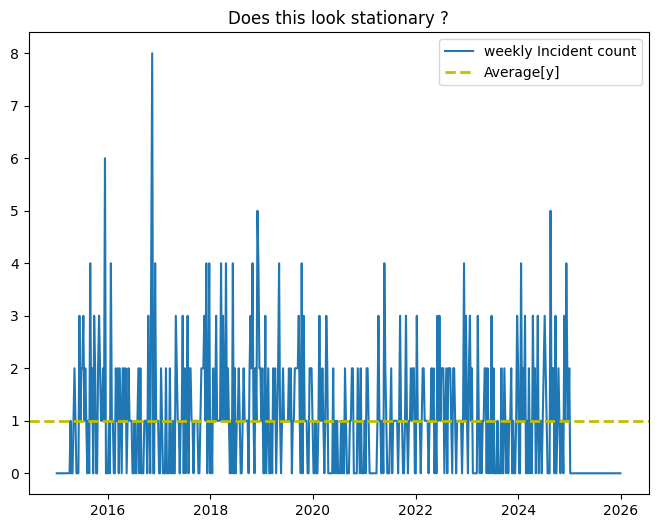

In [57]:
plt.figure(figsize=(8, 6))
plt.plot(df_weekly['Incident_Count'])
plt.title("Does this look stationary ?")

plt.axhline(y=df_weekly['Incident_Count'].mean(), color='y', linestyle='--', linewidth=2)
plt.legend(labels = [ 'weekly Incident count','Average[y]'])

In [58]:
df_diff = df_weekly.diff(1).dropna()

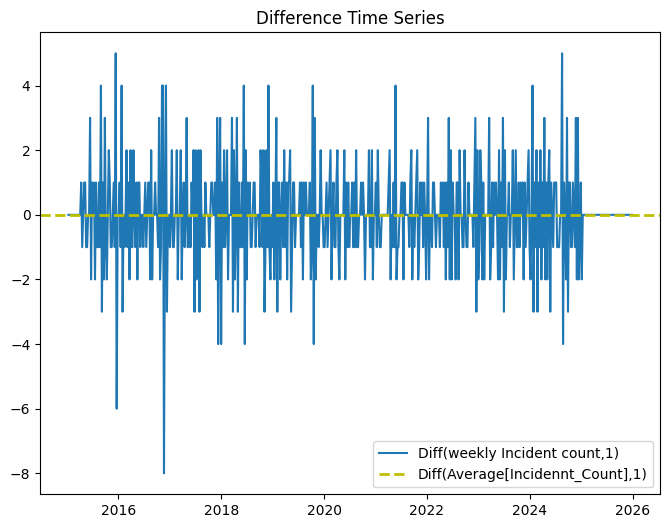

In [59]:
df_diff = df_weekly['Incident_Count'].diff(1).dropna()
plt.figure(figsize=(8, 6))
plt.plot(df_diff,)
plt.title("Difference Time Series")

plt.axhline(y= df_diff.mean(), color='y', linestyle='--', linewidth=2)
plt.legend(labels = [ 'Diff(weekly Incident count,1)','Diff(Average[Incidennt_Count],1)'])

## Stationarity for Multivariate Time Series

Recall that stationarity is an important feature of time series data and that a stationary time series has properties that do not depend on time. In particular, the mean and variance are independent of time.

As in the univariate case, when looking at multivariate data, we need each column to be a stationary time series in order to be able to apply many common time series models.

To do this, we use the Augmented Dickey-Fuller test, which is a statistical test for stationarity.

Write a function, adf_test which does the following:
Takes in input of a column of a dataframe, df_col.

Define dftest to be the result of applying the function adfuller() to df_col.

Set p to store the p-value. This will be contained as one of the entries in the dftest tuple.

Creates the variable result in the following way: if p<=0.05 it contains the string "column_name is stationary", otherwise contains the string "column_name is not stationary".

returns result

One example of an accepted output is the following: 'Global_active_power is stationary'

Note: The Augmented Dickey-Fuller test generates a tuple consisting of 6 parameters:

the ADF test statistic the p-value number of lags used number of observations used critical values at 1%, 5%, 10% levels the maximized information criterion (icbest). Hint: to get the column name you can use df_col.name

In [60]:
from statsmodels.tsa.stattools import adfuller

df_test = adfuller(df_weekly['Incident_Count'])
df_test[0]

np.float64(-5.658732097367188)

An Augmented Dickey-Fuller (ADF) test statistic of -7.95 strongly indicates that your time series data is stationary.
Because the ADF test is a one-tailed test where a more negative value implies stronger evidence against non-stationarity, a score of -7.95 is exceptionally low. It will comfortably sit below all standard critical values (such as -3.43 for 1%, -2.86 for 5%, and -2.57 for 10%).
How to Interpret this Result
• Null Hypothesis (H₀): The series has a unit root (it is non-stationary).

• Actual Result: Your test statistic (-7.95) is much smaller (more negative) than the critical values.

• Conclusion: You reject the null hypothesis (H₀). Your time series does not have a unit root, meaning it is stationary.

• Expected p-value: The corresponding p-value for a statistic this negative will be extremely close to 0 (far below the standard α = 0.05 threshold). Since your data is stationary, its statistical properties like mean and variance are constant over time, making it safe to use directly in forecasting models like ARIMA or VAR without further differencing.

In [61]:
from statsmodels.tsa.stattools import adfuller
# Add your code below

def adf_test(df_col):
    dftest = adfuller(df_col)
    adf_stat = df_test[0]
    p = dftest[1]
    if p <= 0.05:
        result = f"{df_col.name}: is stationary"
    else:
        result = f"{df_col.name}: is not stationary"
    return result

In [62]:
for i in range(df_weekly.shape[1]):
     print(adf_test(df_weekly.iloc[:,i]))

Daily Tmean °C: is stationary
Rainfall mm 1 dpl no traces: is stationary
Sunshine duration h: is stationary
Air frost 0/1: is stationary
Incident_Count: is stationary


### Cross correlation

The final aspect we need to consider before building our model is the correlations amongst features. There are several ways to consider the correlation between time series including Pearson correlation, Spearman correlation, and cross-correlation functions.

Note that when two time series variables are non-stationary, they may show strong correlation even through the underlying processes have no casual relationships. This strong correlation may be purely caused by the fact that the two time series variables have non-constant mean. This phenomenon is called spurious relationship and is worth considering in the non-stationary case.

For extra material on quantifying correlation see the link here.

### SPEARMAN ASSESMENT:

Monotonic Association: Measures if variables increase/decrease together, even if not linearly. Rank-Based: Ranks data from low to high, calculating Pearson’s correlation on these ranks.

In [63]:
weekly_corr = df_weekly.corr(method = 'spearman')
weekly_corr

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h,Air frost 0/1,Incident_Count
Daily Tmean °C,1.000000,-0.136633,0.407899,-0.419648,0.018477
Rainfall mm 1 dpl no traces,-0.136633,1.000000,-0.399407,0.013757,0.036252
Sunshine duration h,0.407899,-0.399407,1.000000,-0.122715,0.007753
Air frost 0/1,-0.419648,0.013757,-0.122715,1.000000,-0.033159
Incident_Count,0.018477,0.036252,0.007753,-0.033159,1.000000


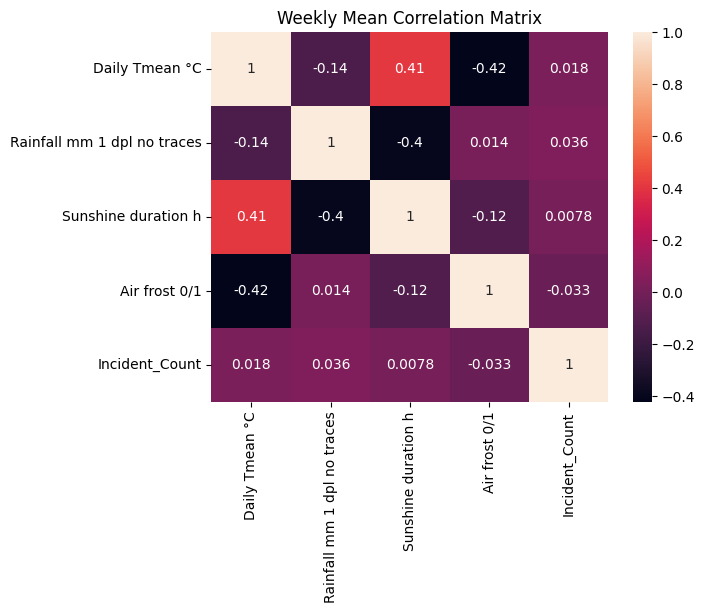

In [64]:
hm1 = sns.heatmap(weekly_corr, annot=True,
         xticklabels=df_weekly.columns,
         yticklabels=df_weekly.columns);
hm1.set_title('Weekly Mean Correlation Matrix');

Building the Model: VAR Vector autoregression (VAR) is a very flexible and easy to use model for the analysis of multivariate time series. It is an extension of the univariate AR model.

In a VAR model, each variable is a linear function of the past values of itself and the past values of all the other variables.

Consider the case of bivariate data, that is we have 2 time series of interest. Using 1 lag, VAR will model the following:

y1(t) = a1 + w11 * y1(t-1) + w12 y2(t-1) + e1(t-1) and

y2(t) = a2 + w21 * y1(t-1) + w22 y2(t-1) + e2(t-1) Here:

a1 and a2 are the constant terms, w11, w12, w21, and w22 are the coefficients, e1 and e2 are the error terms This can be extended and written in matrix notation for lag up to p as:

y(t) = a + w1 * y(t-1) + ... + wp * y(t-p) + e(t), where now, y is a vector containing y1, y2, all the way up to yp, and w1 is a vector containing the values w11, w12, all the way up to wp. Lastly e is a vector containing all of the error terms.

You can find the documentation about the VAR model here.

We will now consider 3 types of forecasting problems as assess how the VAR model performs in each.

Predicting 1 month = 4 weeks ahead based on all historical data. This is a fairly short-term forecast.

Predicting 2 months = 8 weeks ahead based on all historical data. This is a much longer term forecast.

Multi-step forecast for 1 month. This involves making a prediction for one time step, taking the prediction, and feeding it into the model as an input in order to predict the subsequent time step. This process is repeated until the desired number of steps have been forecasted. In practice this can be very useful, especially in conjunction with other forecasts as it allows us to make full use of the current and updated data.

Predicting 1 week ahead. 10. Create a copy of the daily_mean dataframe and store it in model_ds.

In [65]:
df_weekly #= df_weekly.set_index('Date')

model_ds = df_weekly.copy()
model_ds.head(2)

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h,Air frost 0/1,Incident_Count
Date,,,,,
2015-01-04,2.8,0.2,0.0,1,0.0
2015-01-11,6.3,0.2,3.3,0,0.0


Create two new DataFrames. The first one, ds_train1, with all the rows of model_ds except for the last 4. The second one, ds_test1, with only the last 4 rows of model_ds.

In [66]:
ds_train1 = model_ds.iloc[:-4]
ds_test1 = model_ds.iloc[-4:]

In [67]:
ds_train1.tail(2)

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h,Air frost 0/1,Incident_Count
Date,,,,,
2025-11-23,6.8,0.5,6.6,0,0.0
2025-11-30,6.1,2.2,7.0,0,0.0


In [68]:
ds_test1.head(2)

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h,Air frost 0/1,Incident_Count
Date,,,,,
2025-12-07,11.05,4.7,0.0,0,0.0
2025-12-14,6.40,0.0,2.0,0,0.0


Using the function VAR, define the model using ds_train1.
Then fit via the .fit() function and define the result as model1_fit.¶

In [69]:
from statsmodels.tsa.api import VAR
# Define themodel:
model1 = VAR(ds_train1)
model1_fit = model1.fit()
model1_fit

Create an array prediction1 that contains the predictions on the 4 values of ds_test1.

You can use the forecast function with parameters model1_fit.endog, and steps as the length for which we wish to forecast.

Note: model1_fit.endog contains an np array of ds_train1 and so you can also use np.asarray(ds_train1).

In [70]:
steps = len(ds_test1)
prediction1 = model1_fit.forecast(y = model1_fit.endog, steps = steps)
# If you specifically need it as a numpy array explicitly
prediction1 = np.asarray(prediction1)
prediction1

array([[7.36360971, 1.93576659, 3.78731255, 0.10728275, 0.81302217],
       [8.26443667, 2.03305785, 3.67169191, 0.11603044, 0.9916878 ],
       [8.97898223, 1.98778281, 3.85401707, 0.10784943, 1.0148939 ],
       [9.54183548, 1.94934553, 4.04273713, 0.09944018, 1.01707317]])

You can notice that the prediction contains a large array of forecasts for each of the columns in our dataset. We are interested in column 0. Therefore we define the below function transform_prediction which converts the model forecast result to an array of univariate predictions for the Global_active_power.

In [71]:
def transform_prediction(prediction):
    return [prediction[i][0] for i in range(len(prediction))]

In [72]:
predictions_1month = transform_prediction(prediction1)
predictions_1month

[np.float64(7.3636097113803745),
 np.float64(8.264436665773786),
 np.float64(8.978982234240368),
 np.float64(9.541835481215744)]

In [73]:
df_weekly

,Daily Tmean °C,Rainfall mm 1 dpl no traces,Sunshine duration h,Air frost 0/1,Incident_Count
Date,,,,,
2015-01-04,2.80,0.2,0.0,1,0.0
2015-01-11,6.30,0.2,3.3,0,0.0
2015-01-18,2.60,0.0,4.3,0,0.0
2015-01-25,5.00,0.0,1.8,0,0.0
2015-02-01,3.40,0.0,2.1,0,0.0
...,...,...,...,...,...
2025-11-30,6.10,2.2,7.0,0,0.0
2025-12-07,11.05,4.7,0.0,0,0.0
2025-12-14,6.40,0.0,2.0,0,0.0


In [74]:
%run time_series_metrics.ipynb

In [75]:
obs = 8

In [76]:

VAR_preds = VAR_forecast(df_weekly, n_obs = obs)
metrics(VAR_preds, model_ds, n_obs = obs,  model_name="VAR")


566
567
568
569
570
571
572
573


,VAR model: 8 obs
MAE,8.726530e+00
MAPE,3.930080e+16
RMSE,8.839647e+00
SMAPE,2.000000e+02


In [77]:
VAR_preds = VAR_forecast(df_weekly, n_obs = obs)
VAR_metrics = metrics(VAR_preds, model_ds, n_obs = obs,  model_name="VAR")
VAR_metrics

566
567
568
569
570
571
572
573


,VAR model: 8 obs
MAE,8.726530e+00
MAPE,3.930080e+16
RMSE,8.839647e+00
SMAPE,2.000000e+02


In [78]:
VAR_preds = VAR_forecast(df_weekly, n_obs = obs);
metrics(VAR_preds, model_ds, n_obs = obs,  model_name="VAR");

566
567
568
569
570
571
572
573


The mean residual value is:  -8.72653017242341


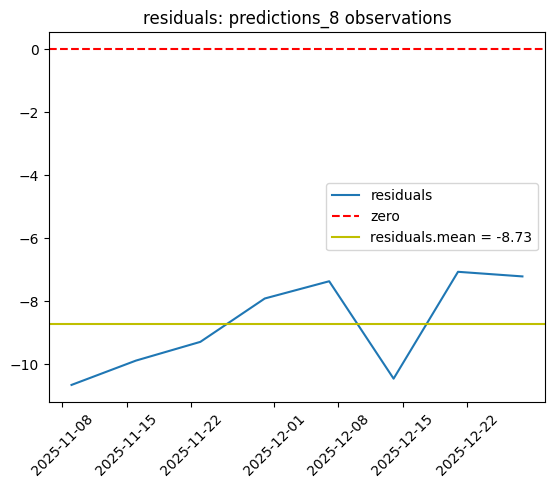

In [79]:
## fit_residuals = time_series[optlag:].values.flatten() - prediction
#.iloc[-n_obs:]
n_obs = obs
fit_residuals = model_ds['Incident_Count'].iloc[-n_obs:].values.flatten() - VAR_preds
print("The mean residual value is: ", np.mean(fit_residuals))

# Plot the result


plt.plot(fit_residuals)
plt.xticks(rotation=45)
plt.axhline(y =0, color = 'r', linestyle='--')
plt.axhline(np.mean(fit_residuals), color = 'y', label = 'residuals.mean()')
plt.title(f"residuals: predictions_{n_obs} observations")
plt.legend(labels = ['residuals', 'zero', f'residuals.mean = {np.mean(fit_residuals):.2f}'])
plt.show()

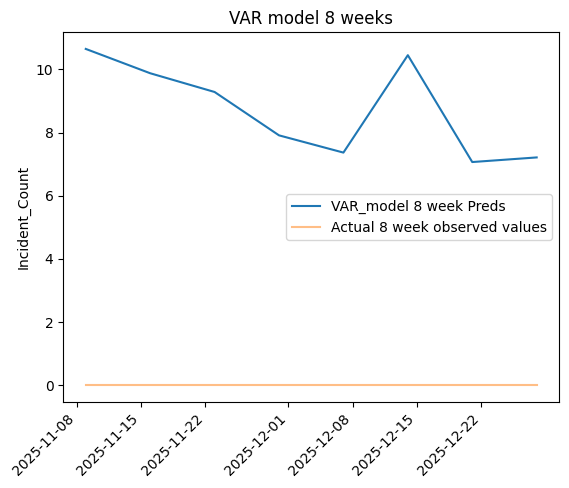

In [80]:
plt.plot(VAR_preds, label = f'VAR_model {obs} week Preds' )
#plt.plot(df_weekly[-n_obs:]['Incident_Count'],label = f'Actual {obs} week observed values')
plt.plot(df_weekly['Incident_Count'][-n_obs:],label = f'Actual {obs} week observed values', alpha = 0.5)

plt.title(f'VAR model {obs} weeks')
plt.ylabel('Incident_Count')
plt.xticks(rotation=45, ha='right')
plt.legend()

plt.show()


## AUTOREGRESSIVE MODELS

In [81]:
from statsmodels.tsa.ar_model import ar_select_order

In [82]:
time_series = df_weekly['Incident_Count']

In [83]:
from statsmodels.tsa.ar_model import ar_select_order

mod = ar_select_order(time_series, maxlag=12, ic="aic")
optlag = max(mod.ar_lags)
print("Optimal p =", optlag)

Optimal p = 7


In [84]:
ar = tsa.AutoReg(time_series, lags=optlag)
ar_result = ar.fit()
AR_prediction = ar_result.predict(start=optlag)

In [85]:
y_true, AR_preds = time_series[optlag:], AR_prediction.iloc[-n_obs:]

In [86]:
optlag

7

In [87]:
y_true[-n_obs:]

Date
2025-11-09    0.0
2025-11-16    0.0
2025-11-23    0.0
2025-11-30    0.0
2025-12-07    0.0
2025-12-14    0.0
2025-12-21    0.0
2025-12-28    0.0
Freq: W-SUN, Name: Incident_Count, dtype: float64

In [88]:
#metrics(preds = AR_prediction, model_ds, optlag,  "VAR")
AR_metrics = metrics(AR_preds, model_ds[-n_obs:], n_obs = n_obs,  model_name = "AR")
AR_metrics

,AR model: 8 obs
MAE,4.923840e-01
MAPE,2.217500e+15
RMSE,4.923840e-01
SMAPE,2.000000e+02


## ARMA(p,q)¶

In [89]:
param_choice = tsa.arma_order_select_ic(
    time_series, max_ar = 5, max_ma =5, ic="aic", trend="c"
)
print("ARMA(p,q) =", param_choice["aic_min_order"], "is the best.")
param_choice["aic_min_order"]

C:\Users\pw347789\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\pw347789\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\pw347789\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\pw347789\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_re

ARMA(p,q) = (np.int64(3), np.int64(4)) is the best.


C:\Users\pw347789\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


(np.int64(3), np.int64(4))

C:\Users\pw347789\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


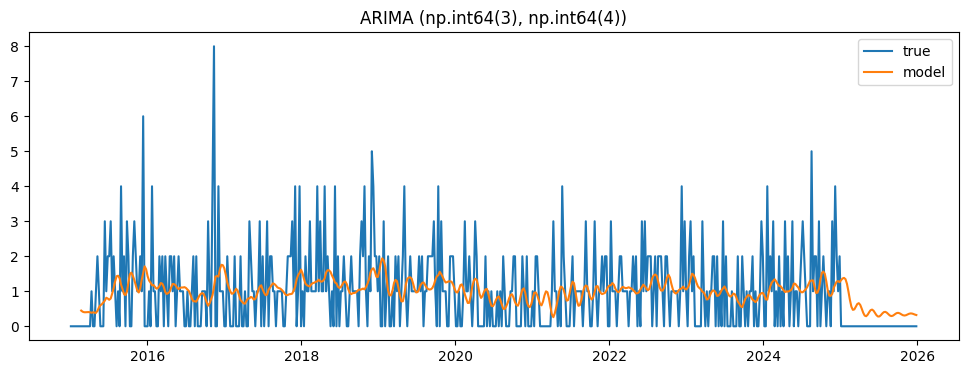

In [90]:
arma = tsa.ARIMA(
    time_series,
    order=(param_choice["aic_min_order"][0], 0, param_choice["aic_min_order"][1]),
)
arma_result = arma.fit()
ARIMA_prediction = arma_result.predict(start=optlag)

plt.figure(figsize=(12, 4))
plt.plot(time_series, label="true")
plt.plot(ARIMA_prediction, label="model")
plt.title(f"ARIMA {param_choice["aic_min_order"]}")
plt.legend()

#print("MAE = {0:.3f}".format(mean_absolute_error(time_series[2:], prediction)))

In [91]:
y_true, preds = time_series[optlag:], ARIMA_prediction[-n_obs:]
ARIMA_metrics = metrics(preds, model_ds[-n_obs:], n_obs= obs , model_name = 'ARIMA')
ARIMA_metrics

,ARIMA model: 8 obs
MAE,3.434547e-01
MAPE,1.546782e+15
RMSE,3.439245e-01
SMAPE,2.000000e+02


### SARIMA(p,d,q)

In [92]:
print("AR model Optimal p =", optlag)

AR model Optimal p = 7


In [93]:
print("ARMA(p,q) =", param_choice["aic_min_order"], "is the best.")

ARMA(p,q) = (np.int64(3), np.int64(4)) is the best.


In [94]:
# The final value in the seasonal order influences the p, d, and q parameters.
# For example, a value of 12 for monthly data suggests a yearly seasonal cycle.
# Likewise a value of 52 for weekly data suggests a yearly seasonal cycle
from statsmodels.tsa.statespace.sarimax import SARIMAX

mod = SARIMAX(
    time_series,
    # trend parameter='c': we have a constan
    trend="c",
    #order=(1,0,1),   # Our AR parameter is 1, our MA parameter is 1, and as our data is stationary, we difference 0 times
    
    seasonal_order=(5, 0, 4, 12), #(p,d,q,s) seasonal_order=(1,0,1,12): Our data is annually seasonal and it's recorded monthly, so 12 gives the frequency
    enforce_stationarity=False,
    enforce_invertibility=False,
)



# The code for this is given at the end of this notebook
# enforce_stationarity and enforce_stationarity are False. These are mathematical properties that typically hold, but
# setting them to false allows us to explore all parameter sets.


## Breakdown of the Parameters
• P = 1 (Seasonal Autoregressive order): Uses 1 seasonal lag. It relates the current value to the value from 1 seasonal cycle ago (t - 12).

• D = 0 (Seasonal differencing order): Performs no seasonal differencing. The seasonal pattern of the time series is already stationary without needing subtraction across seasons.

• Q = 1 (Seasonal Moving Average order): Uses 1 seasonal moving average lag. It includes the error term from 1 seasonal period ago (t - 12) in the prediction.

• s = 12 (Periodicity / Season length): Defines the length of a full seasonal cycle. For example, this represents 12 months in a yearly cycle when working with monthly data.

In [95]:
# Fit the model
sarima_result = mod.fit()

In [96]:
# Form a prediction, starting at the maximum value of the p, q parameters
SARIMA_prediction = sarima_result.predict(start=3)
SARIMA_prediction

Date
2015-01-25    0.291143
2015-02-01    0.291143
2015-02-08    0.291143
2015-02-15    0.291143
2015-02-22    0.291143
                ...   
2025-11-30    0.723702
2025-12-07    0.678387
2025-12-14    0.852319
2025-12-21    0.665680
2025-12-28    0.751699
Freq: W-SUN, Name: predicted_mean, Length: 571, dtype: float64

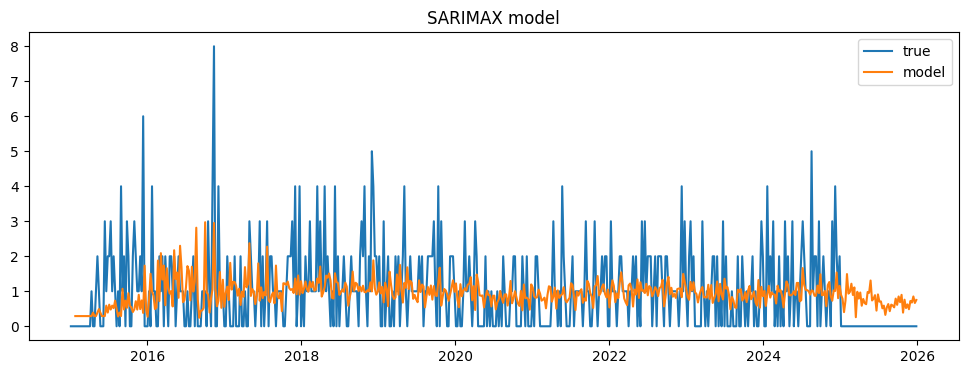

In [97]:
plt.figure(figsize=(12, 4))
plt.plot(time_series, label="true")
plt.plot(SARIMA_prediction, label="model")
plt.legend()

plt.title("SARIMAX model")
plt.show()


In [98]:
y_true, preds = time_series[-n_obs:], SARIMA_prediction[-n_obs:]
SARIMA_metrics = metrics(preds, model_ds[-n_obs:], n_obs=obs , model_name = 'SARIMA')
SARIMA_metrics

,SARIMA model: 8 obs
MAE,6.631514e-01
MAPE,2.986568e+15
RMSE,6.725250e-01
SMAPE,2.000000e+02


## Selecting parameters for the seasonal order
In order to choose the best possible parameters for our seasonal order in the SARIMAX model, we can use the below code to effectively grid search over a range of parameters and identify the best one in terms of MAE.

In [99]:
# Note that this code takes a while to run due to searching over a large parameter space.

import warnings
import itertools

warnings.filterwarnings("ignore")  # specify to ignore warning messages

# Set p, and q to take values from 0 to 3.
p = q = range(0, 3)
# Set d to take values from 0 to 1.
d = range(0, 3)

In [100]:
# Initialise a list to store the mean absolute errors for each parameter set
mae_values = []

# Generate all different combinations of p, q and q triplets
pdq = list(itertools.product(p, d, q))
# Show what pdq is; we see that its a list of all possible combinations of p, d and q
#
len(pdq)
pdq

[(0, 0, 0),
 (0, 0, 1),
 (0, 0, 2),
 (0, 1, 0),
 (0, 1, 1),
 (0, 1, 2),
 (0, 2, 0),
 (0, 2, 1),
 (0, 2, 2),
 (1, 0, 0),
 (1, 0, 1),
 (1, 0, 2),
 (1, 1, 0),
 (1, 1, 1),
 (1, 1, 2),
 (1, 2, 0),
 (1, 2, 1),
 (1, 2, 2),
 (2, 0, 0),
 (2, 0, 1),
 (2, 0, 2),
 (2, 1, 0),
 (2, 1, 1),
 (2, 1, 2),
 (2, 2, 0),
 (2, 2, 1),
 (2, 2, 2)]

In [101]:
# Generate all different combinations of seasonal p, q and q triplets
seasonal_pdq = [(x[0], x[1], x[2], 4) for x in list(itertools.product(p, d, q))]
# We can see we've appended 12 onto each triple so that it's in the format SARIMAX expects
#seasonal_pdq

In [102]:
# Iterate over each option in seasonal_pqd
for param_seasonal in seasonal_pdq:
    # Generate a SARIMA model with the selected parameters for the seasonal order
    mod = tsa.statespace.SARIMAX(
        time_series,
        trend="c",
        order=(1, 0, 1),
        seasonal_order=param_seasonal,
        enforce_stationarity=False,
        enforce_invertibility=False,
    )

    # Fit and predict the model
    results = mod.fit()
    prediction = results.predict(start=3)
    # If the prediction has resulted in any NaNs we want to ignore this parameter set so set the mae very high
    if np.isnan(prediction).any():
        mae = 1e100
    else:
        # Otherwise we can store the mae
        mae = mean_absolute_error(time_series[3:], prediction)
    # Append the mae to our list
    mae_values.append(mae)

In [103]:
# Now we can find the minimum value in our list of errors and get the corresponding seasonal parameters
min_index = mae_values.index(min(mae_values))
best_seasonal_params = seasonal_pdq[min_index]
print(best_seasonal_params)
best_seasonal_params

(2, 0, 2, 4)


(2, 0, 2, 4)

## Rerun model with these parameters:

In [104]:
# The final value in the seasonal order influences the p, d, and q parameters.
# For example, a value of 12 for monthly data suggests a yearly seasonal cycle.
# Likewise a value of 52 for weekly data suggests a yearly seasonal cycle
from statsmodels.tsa.statespace.sarimax import SARIMAX

mod = SARIMAX(
    time_series,
    # trend parameter='c': we have a constan
    trend="c",
    # order=(1,0,1): Our AR parameter is 1, our MA parameter is 1, and as our data is stationary, we difference 0 times
    order=(1, 0, 1),  # order(p,d,q)
    seasonal_order=  best_seasonal_params,   #(1, 0, 1, 4), #(p,d,q,s) seasonal_order=(1,0,1,12): Our data is annually seasonal and it's recorded monthly, so 12 gives the frequency
    enforce_stationarity=False,
    enforce_invertibility=False,
)



# The code for this is given at the end of this notebook
# enforce_stationarity and enforce_stationarity are False. These are mathematical properties that typically hold, but
# setting them to false allows us to explore all parameter sets.

In [105]:
# Fit the model
sarima_result = mod.fit()

In [106]:
# Form a prediction, starting at the maximum value of the p, q parameters
SARIMA_2_prediction = sarima_result.predict(start=3)

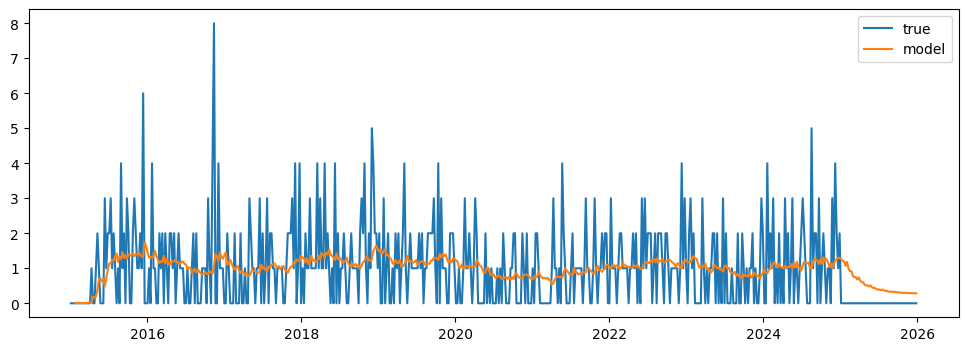

In [107]:
plt.figure(figsize=(12, 4))
plt.plot(time_series, label="true")
plt.plot(SARIMA_2_prediction, label="model")
plt.legend()
plt.show()

# add your code here to show the MAE
#MAE_SARIMAX = mean_absolute_error(time_series[-n_obs:], prediction) 

#MAPE_SARIMAX = mean_absolute_percentage_error(time_series[-n_obs:], prediction)
#RMSE_SARIMAX = np.sqrt(mean_squared_error(time_series[-n_obs:], prediction))

#print("MAE_SARIMAX = {0:.3f}".format(MAE_SARIMAX))
#print("MAPE_SARIMAX = {0:.3f}".format(MAPE_SARIMAX))
#print("RMSE_SARIMAX = {0:.3f}".format(RMSE_SARIMAX))

In [108]:
y_true, preds = time_series[-n_obs:], SARIMA_2_prediction[-n_obs:]
SARIMA_tuned_metrics = metrics(preds, model_ds[-n_obs:], n_obs=obs , model_name = 'SARIMA_tuned')

In [109]:
SARIMA_tuned_metrics

,SARIMA_tuned model: 8 obs
MAE,2.907343e-01
MAPE,1.309351e+15
RMSE,2.907874e-01
SMAPE,2.000000e+02


In [110]:
#SARIMA_metrics.join(SARIMA_tuned_metrics, shared_index = True)

TS_metrics = AR_metrics.join([VAR_metrics, SARIMA_metrics, SARIMA_tuned_metrics])
TS_metrics

,AR model: 8 obs,VAR model: 8 obs,SARIMA model: 8 obs,SARIMA_tuned model: 8 obs
MAE,4.923840e-01,8.726530e+00,6.631514e-01,2.907343e-01
MAPE,2.217500e+15,3.930080e+16,2.986568e+15,1.309351e+15
RMSE,4.923840e-01,8.839647e+00,6.725250e-01,2.907874e-01
SMAPE,2.000000e+02,2.000000e+02,2.000000e+02,2.000000e+02


In [112]:
TS_metrics.to_csv('TS_metrics.csv')